<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

            Position  Level   Salary
0   Business Analyst      1    45000
1  Junior Consultant      2    50000
2  Senior Consultant      3    60000
3            Manager      4    80000
4    Country Manager      5   110000
5     Region Manager      6   150000
6            Partner      7   200000
7     Senior Partner      8   300000
8            C-level      9   500000
9                CEO     10  1000000 

Model                       R2          RMSE   Predict level 6.5
Linear (degree 1)       0.6690        163389              330379
Polynomial (degree 2)   0.9162         82212              189498
Polynomial (degree 3)   0.9812         38932              133259
Polynomial (degree 4)   0.9974         14503              158862

Linear equation: Salary = 80879 x Level + (-195333)


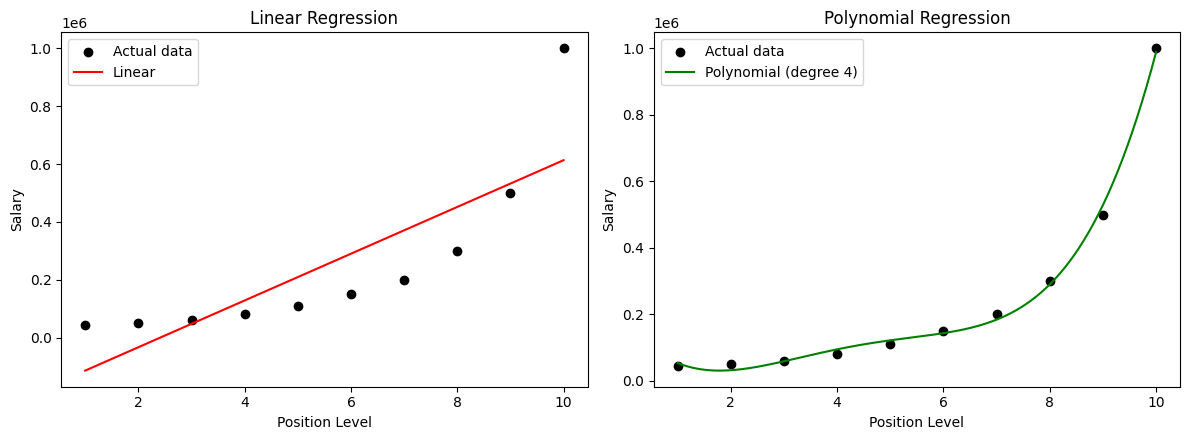

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Dataset: Position Salaries (Create if missing)
csv_filename = 'Position_Salaries.csv'
if not os.path.exists(csv_filename):
    data = {
        'Position': [
            'Business Analyst', 'Junior Consultant', 'Senior Consultant', 'Manager',
            'Country Manager', 'Region Manager', 'Partner', 'Senior Partner',
            'C-level', 'CEO'
        ],
        'Level': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
        'Salary': [45000, 50000, 60000, 80000, 110000, 150000, 200000, 300000, 500000, 1000000]
    }
    pd.DataFrame(data).to_csv(csv_filename, index=False)

# ---- 1. Load CSV ----
df = pd.read_csv(csv_filename)
print(df, "\n")
x = df['Level'].values.astype(float)
y = df['Salary'].values.astype(float)

# ---- 2. Fit a polynomial of given degree (degree 1 = Linear Regression) ----
def fit(x, y, degree):
    # columns: 1, x, x^2, ... x^degree
    A = np.vander(x, degree + 1, increasing=True)
    # least squares solution: w = (A^T A)^-1 A^T y
    return np.linalg.pinv(A.T @ A) @ A.T @ y

def predict(w, x):
    A = np.vander(np.atleast_1d(x), len(w), increasing=True)
    return A @ w

# ---- 3. Evaluate ----
def metrics(actual, predicted):
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
    return rmse, r2

# ---- 4. Compare Linear and Polynomial models ----
models = {}
print(f"{'Model':<22}{'R2':>8}{'RMSE':>14}{'Predict level 6.5':>20}")
for degree in [1, 2, 3, 4]:
    w = fit(x, y, degree)
    models[degree] = w
    rmse, r2 = metrics(y, predict(w, x))
    name = 'Linear (degree 1)' if degree == 1 else f'Polynomial (degree {degree})'
    print(f"{name:<22}{r2:8.4f}{rmse:14.0f}{predict(w, 6.5)[0]:20.0f}")

# ---- 5. Linear equation ----
w1 = models[1]
print(f"\nLinear equation: Salary = {w1[1]:.0f} x Level + ({w1[0]:.0f})")

# ---- 6. Plot ----
xs = np.linspace(x.min(), x.max(), 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(x, y, color='black', label='Actual data')
ax[0].plot(xs, predict(models[1], xs), color='red', label='Linear')
ax[0].set_title('Linear Regression')

ax[1].scatter(x, y, color='black', label='Actual data')
ax[1].plot(xs, predict(models[4], xs), color='green', label='Polynomial (degree 4)')
ax[1].set_title('Polynomial Regression')

for a in ax:
    a.set_xlabel('Position Level')
    a.set_ylabel('Salary')
    a.legend()

plt.tight_layout()
plt.show()